# Генетический алгоритм для функции Михалевича

В этом ноутбуке реализована минимизация функции

$$f(x) = -\sum_{i=1}^{d} \sin(x_i)\left[\sin\left(\frac{i x_i^2}{\pi}\right)\right]^{20}, \qquad x \in [0, \pi]^d.$$

Используются вещественные векторы, три вида селекции, арифметический, BLX и SBX-кроссоверы, гауссова мутация и элитизм. Готовые оптимизаторы не применяются.

Критерий остановки — точное число вычислений целевой функции. Начальная популяция также входит в бюджет.

## Параметры

`GAConfig` хранит все параметры запуска. Значение `seed` делает запуск воспроизводимым, а `budget` задаёт общее число вычислений функции.

Основные значения для экспериментов: размерность 9, популяция 100, бюджет 10 000, турнирная селекция с размером турнира 3, SBX, вероятность кроссовера 0.9, вероятность мутации координаты 0.1, начальное $\sigma=0.1$ и одна элитная особь.

In [1]:
import math
from dataclasses import dataclass
from typing import Literal

import matplotlib.pyplot as plt
import numpy as np


@dataclass
class GAConfig:
    dim: int = 9
    population_size: int = 100
    budget: int = 10_000
    tournament_size: int = 3
    selection: Literal["tournament", "rank", "roulette"] = "tournament"
    crossover: Literal["arithmetic", "blx", "sbx"] = "sbx"
    crossover_prob: float = 0.9
    mutation_prob: float = 0.1
    mutation_sigma: float = 0.1
    adaptive_sigma: bool = False
    adaptive_sigma_factor: float = 1.01
    blx_alpha: float = 0.5
    sbx_eta: float = 15.0
    elitism: int = 1
    seed: int = 42
    lower: float = 0.0
    upper: float = math.pi

    def __post_init__(self) -> None:
        if self.dim < 1:
            raise ValueError("dim must be positive")
        if self.population_size < 2:
            raise ValueError("population_size must be at least 2")
        if self.budget < self.population_size:
            raise ValueError("budget must be at least population_size")
        if not 1 <= self.tournament_size <= self.population_size:
            raise ValueError("tournament_size must be in [1, population_size]")
        if not 0 <= self.elitism < self.population_size:
            raise ValueError("elitism must be in [0, population_size)")
        if not 0 <= self.crossover_prob <= 1:
            raise ValueError("crossover_prob must be in [0, 1]")
        if not 0 <= self.mutation_prob <= 1:
            raise ValueError("mutation_prob must be in [0, 1]")
        if self.mutation_sigma < 0:
            raise ValueError("mutation_sigma must be non-negative")
        if self.adaptive_sigma_factor <= 0:
            raise ValueError("adaptive_sigma_factor must be positive")
        if self.blx_alpha < 0:
            raise ValueError("blx_alpha must be non-negative")
        if self.sbx_eta <= 0:
            raise ValueError("sbx_eta must be positive")
        if self.lower >= self.upper:
            raise ValueError("lower must be less than upper")


## Целевая функция

Функция принимает как один вектор, так и матрицу, где каждая строка — отдельная особь. Векторизованное вычисление по строкам сокращает код и ускоряет оценку популяции.

Множитель $\sin^{20}(\cdot)$ образует узкие области заметных значений, поэтому случайному поиску трудно обнаружить хорошие решения.

In [2]:
def michalewicz(x: np.ndarray) -> np.ndarray | np.float64:
    x = np.asarray(x, dtype=float)
    i = np.arange(1, x.shape[-1] + 1, dtype=float)
    terms = np.sin(x) * np.power(np.sin(i * x * x / np.pi), 20)
    return -np.sum(terms, axis=-1)


## Операторы алгоритма

При **турнирной селекции** выбирается лучшая из нескольких случайных особей. При **ранговой селекции** вероятность пропорциональна рангу: лучшая особь получает наибольший вес. **Рулеточная селекция** использует значения функции после сдвига, необходимого для минимизации.

**Арифметический кроссовер** строит выпуклые комбинации родителей. **BLX** расширяет интервал между родителями на $\alpha |p_1-p_2|$. **SBX** использует случайный коэффициент $\beta$, распределение которого управляется параметром $\eta$. Перед применением формулы для каждой координаты с вероятностью 0.5 родители меняются местами, как в эталонной реализации из NSGA-II (Deb): пары значений потомков при этом неизменны, меняется лишь их распределение между двумя потомками.

Мутация добавляет к каждой координате нормальный шум с вероятностью $p_m$. После этого все координаты обрезаются к $[0, \pi]$, включая потомков, у которых мутация не произошла.

Адаптация $\sigma$ — простая эвристика: после улучшения глобального лучшего значения масштаб умножается на `adaptive_sigma_factor`, иначе делится на него. Это не классическое правило 1/5, поскольку доля успешных мутаций не вычисляется.

In [3]:
class GeneticAlgorithm:
    def __init__(self, config: GAConfig):
        self.cfg = config
        self.rng = np.random.default_rng(config.seed)
        self.n_evals = 0
        self.best_history: list[float] = []
        self.mean_history: list[float] = []
        self.worst_history: list[float] = []
        self.sigma_history: list[float] = []
        self.eval_history: list[int] = []
        self.current_sigma = config.mutation_sigma

    def _evaluate_population(self, population: np.ndarray) -> np.ndarray:
        self.n_evals += len(population)
        return michalewicz(population)

    def _tournament_select(
        self, population: np.ndarray, fitness: np.ndarray
    ) -> np.ndarray:
        indices = self.rng.choice(
            len(population), size=self.cfg.tournament_size, replace=False
        )
        best_idx = indices[np.argmin(fitness[indices])]
        return population[best_idx].copy()

    def _rank_select(
        self, population: np.ndarray, fitness: np.ndarray
    ) -> np.ndarray:
        ordered = np.argsort(fitness)
        weights = np.arange(len(population), 0, -1, dtype=float)
        probabilities = weights / weights.sum()
        idx = self.rng.choice(ordered, p=probabilities)
        return population[idx].copy()

    def _roulette_select(
        self, population: np.ndarray, fitness: np.ndarray
    ) -> np.ndarray:
        shifted = fitness.max() - fitness
        total = shifted.sum()
        if total <= 0:
            idx = self.rng.integers(len(population))
        else:
            idx = self.rng.choice(len(population), p=shifted / total)
        return population[idx].copy()

    def _select(
        self, population: np.ndarray, fitness: np.ndarray
    ) -> np.ndarray:
        if self.cfg.selection == "tournament":
            return self._tournament_select(population, fitness)
        if self.cfg.selection == "rank":
            return self._rank_select(population, fitness)
        if self.cfg.selection == "roulette":
            return self._roulette_select(population, fitness)
        raise ValueError(f"Unknown selection: {self.cfg.selection}")

    def _arithmetic_crossover(
        self, p1: np.ndarray, p2: np.ndarray
    ) -> tuple[np.ndarray, np.ndarray]:
        alpha = self.rng.random(self.cfg.dim)
        c1 = alpha * p1 + (1.0 - alpha) * p2
        c2 = alpha * p2 + (1.0 - alpha) * p1
        return c1, c2

    def _blx_crossover(
        self, p1: np.ndarray, p2: np.ndarray
    ) -> tuple[np.ndarray, np.ndarray]:
        diff = np.abs(p1 - p2)
        low = np.minimum(p1, p2) - self.cfg.blx_alpha * diff
        high = np.maximum(p1, p2) + self.cfg.blx_alpha * diff
        u1 = self.rng.random(self.cfg.dim)
        u2 = self.rng.random(self.cfg.dim)
        return low + u1 * (high - low), low + u2 * (high - low)

    def _sbx_crossover(
        self, p1: np.ndarray, p2: np.ndarray
    ) -> tuple[np.ndarray, np.ndarray]:
        u = self.rng.random(self.cfg.dim)
        beta = np.where(
            u <= 0.5,
            (2.0 * u) ** (1.0 / (self.cfg.sbx_eta + 1.0)),
            (1.0 / (2.0 * (1.0 - u))) ** (1.0 / (self.cfg.sbx_eta + 1.0)),
        )
        swap = self.rng.random(self.cfg.dim) < 0.5
        p1, p2 = p1.copy(), p2.copy()
        p1[swap], p2[swap] = p2[swap], p1[swap]
        c1 = 0.5 * ((1.0 + beta) * p1 + (1.0 - beta) * p2)
        c2 = 0.5 * ((1.0 - beta) * p1 + (1.0 + beta) * p2)
        return c1, c2

    def _crossover(
        self, p1: np.ndarray, p2: np.ndarray
    ) -> tuple[np.ndarray, np.ndarray]:
        if self.rng.random() > self.cfg.crossover_prob:
            return p1.copy(), p2.copy()
        if self.cfg.crossover == "arithmetic":
            return self._arithmetic_crossover(p1, p2)
        if self.cfg.crossover == "blx":
            return self._blx_crossover(p1, p2)
        if self.cfg.crossover == "sbx":
            return self._sbx_crossover(p1, p2)
        raise ValueError(f"Unknown crossover: {self.cfg.crossover}")

    def _mutate(self, individual: np.ndarray) -> np.ndarray:
        mask = self.rng.random(self.cfg.dim) < self.cfg.mutation_prob
        noise = self.rng.normal(0.0, self.current_sigma, size=self.cfg.dim)
        mutated = individual + mask * noise
        return np.clip(mutated, self.cfg.lower, self.cfg.upper)

    def _adapt_sigma(self, improved: bool) -> None:
        if not self.cfg.adaptive_sigma:
            return
        if improved:
            self.current_sigma *= self.cfg.adaptive_sigma_factor
        else:
            self.current_sigma /= self.cfg.adaptive_sigma_factor
        self.current_sigma = float(np.clip(self.current_sigma, 1e-4, 1.0))

    def _record(self, fitness: np.ndarray, best_fitness: float) -> None:
        self.best_history.append(best_fitness)
        self.mean_history.append(float(np.mean(fitness)))
        self.worst_history.append(float(np.max(fitness)))
        self.sigma_history.append(self.current_sigma)
        self.eval_history.append(self.n_evals)

    def run(self) -> dict:
        cfg = self.cfg
        population = self.rng.uniform(
            cfg.lower, cfg.upper, size=(cfg.population_size, cfg.dim)
        )
        fitness = self._evaluate_population(population)

        best_idx = int(np.argmin(fitness))
        best = population[best_idx].copy()
        best_fitness = float(fitness[best_idx])
        self._record(fitness, best_fitness)

        while self.n_evals < cfg.budget:
            previous_best = best_fitness
            size = min(cfg.population_size, cfg.budget - self.n_evals)
            new_population = []
            elite_indices = np.argsort(fitness)[: min(cfg.elitism, size)]
            for idx in elite_indices:
                new_population.append(population[idx].copy())

            while len(new_population) < size:
                p1 = self._select(population, fitness)
                p2 = self._select(population, fitness)
                c1, c2 = self._crossover(p1, p2)
                new_population.append(self._mutate(c1))
                if len(new_population) < size:
                    new_population.append(self._mutate(c2))

            population = np.asarray(new_population[:size])
            fitness = self._evaluate_population(population)
            gen_best_idx = int(np.argmin(fitness))
            gen_best_fitness = float(fitness[gen_best_idx])
            if gen_best_fitness < best_fitness:
                best_fitness = gen_best_fitness
                best = population[gen_best_idx].copy()

            self._adapt_sigma(best_fitness < previous_best)
            self._record(fitness, best_fitness)

        return {
            "best_x": best.tolist(),
            "best_fitness": best_fitness,
            "n_evals": self.n_evals,
            "best_history": self.best_history,
            "mean_history": self.mean_history,
            "worst_history": self.worst_history,
            "sigma_history": self.sigma_history,
            "eval_history": self.eval_history,
        }


## Случайный поиск

Для базового сравнения используется равномерная случайная выборка. Она получает тот же бюджет и те же начальные значения генератора случайных чисел, что и генетический алгоритм.

В обоих методах `eval_history` связывает лучшее найденное значение с фактическим числом вычислений функции.

In [4]:
def random_search(config: GAConfig) -> dict:
    rng = np.random.default_rng(config.seed)
    best_fitness = math.inf
    best_x = None
    best_history = []
    eval_history = []
    n_evals = 0

    while n_evals < config.budget:
        batch_size = min(config.population_size, config.budget - n_evals)
        batch = rng.uniform(
            config.lower, config.upper, size=(batch_size, config.dim)
        )
        fitness = michalewicz(batch)
        n_evals += batch_size
        idx = int(np.argmin(fitness))
        if fitness[idx] < best_fitness:
            best_fitness = float(fitness[idx])
            best_x = batch[idx].copy()
        best_history.append(best_fitness)
        eval_history.append(n_evals)

    return {
        "best_x": best_x.tolist(),
        "best_fitness": best_fitness,
        "n_evals": n_evals,
        "best_history": best_history,
        "eval_history": eval_history,
    }


## Один запуск

Запустим базовую конфигурацию с адаптацией масштаба мутации. График показывает лучшее найденное значение по мере расходования бюджета.

Лучшее значение: -8.319071
Вычислений функции: 10000 из 10000
Лучшая точка: [2.2021 1.5703 1.2861 1.1121 0.9953 1.571  1.8776 2.078  1.6561]


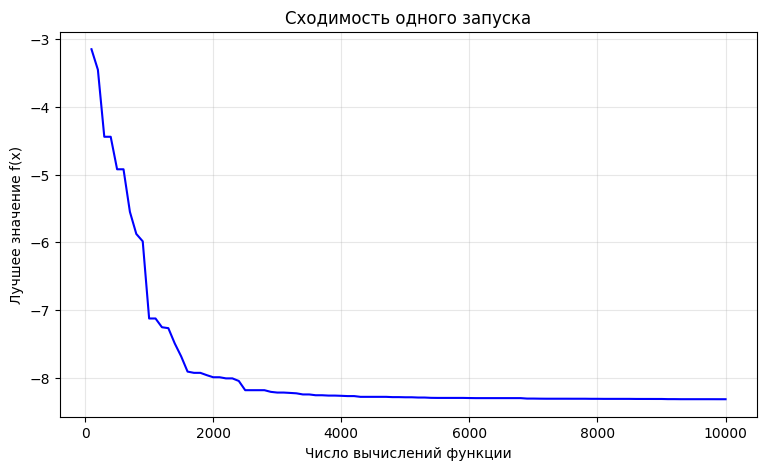

In [5]:
config = GAConfig(crossover="sbx", adaptive_sigma=True, seed=42)
result = GeneticAlgorithm(config).run()

print(f"Лучшее значение: {result['best_fitness']:.6f}")
print(f"Вычислений функции: {result['n_evals']} из {config.budget}")
print(f"Лучшая точка: {np.round(result['best_x'], 4)}")

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(result["eval_history"], result["best_history"], color="blue")
ax.set_xlabel("Число вычислений функции")
ax.set_ylabel("Лучшее значение f(x)")
ax.set_title("Сходимость одного запуска")
ax.grid(alpha=0.3)
plt.show()


Один запуск иллюстрирует работу алгоритма, но не доказывает его эффективность. Серии независимых запусков и статистическое сравнение конфигураций находятся в `02_experiments.ipynb`.